# Closed-loop UUV depth control

This notebook demonstrates the full control loop for an uncrewed underwater vehicle (UUV) that must follow a reference depth through a cave.

| Part | Where it lives |
|---|---|
| Plant (`Submarine`), mission loading (`Mission.from_csv`), loop (`ClosedLoop`) | `uuv_mission/dynamic.py` |
| PD controller (`PDController`) | `uuv_mission/control.py` |

The notebook runs top to bottom: load the mission, build the plant and controller, simulate with random disturbances, then plot and save the result.

## 1. Setup

Make the `uuv_mission` package importable whether the notebook is started from the repository root or from `notebooks/`, then import what we need.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

project_root = Path.cwd()
if not (project_root / "uuv_mission").is_dir():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

from uuv_mission.control import PDController
from uuv_mission.dynamic import ClosedLoop, Mission, Submarine

## 2. Load the mission

`Mission.from_csv` reads the reference depth and the two cave boundaries from `data/mission.csv`. It raises an error if a column is missing or if the reference ever leaves the cave, so a mission that loads is a feasible one.

In [2]:
mission = Mission.from_csv(str(project_root / "data" / "mission.csv"))
print(f"Mission length: {len(mission.reference)} time steps")

Mission length: 100 time steps


## 3. Build the plant, controller and closed loop

The controller is a PD law on the depth error $e[t] = r[t] - y[t]$:

$$u[t] = K_P\, e[t] + K_D\,\big(e[t] - e[t-1]\big), \qquad K_P = 0.15,\; K_D = 0.6,\; e[-1] = 0.$$

`PDController` stores $e[t-1]$ itself, so `ClosedLoop` only calls `step(reference, measurement)` once per time step and `reset()` at the start of each run.

In [3]:
sub = Submarine()
controller = PDController()  # defaults: kp=0.15, kd=0.6
closed_loop = ClosedLoop(sub, controller)

## 4. Simulate

The vehicle is pushed around by random disturbances (Gaussian noise). The random seed is fixed so every run of the notebook, and the saved figure, is reproducible.

In [4]:
SEED = 42
np.random.seed(SEED)
trajectory = closed_loop.simulate_with_random_disturbances(mission)

## 5. Plot and save the result

The trajectory is drawn against the reference and the cave. The figure is saved **before** `plt.show()`: in a notebook `show()` closes the figure, and saving afterwards would write a blank image. The file is written to `figures/trajectory.png` (300 dpi) for the report.

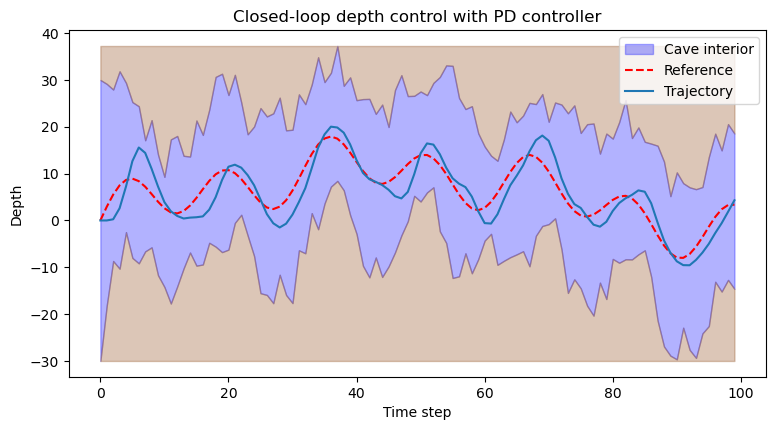

In [5]:
time = np.arange(len(mission.reference))
depth = trajectory.position[:, 1]
rock_top = np.max(mission.cave_height)
rock_bottom = np.min(mission.cave_depth)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.fill_between(time, mission.cave_depth, mission.cave_height, color="blue", alpha=0.3, label="Cave interior")
ax.fill_between(time, rock_bottom, mission.cave_depth, color="saddlebrown", alpha=0.3)
ax.fill_between(time, mission.cave_height, rock_top, color="saddlebrown", alpha=0.3)
ax.plot(time, mission.reference, "r--", label="Reference")
ax.plot(trajectory.position[:, 0], depth, label="Trajectory")
ax.set_xlabel("Time step")
ax.set_ylabel("Depth")
ax.set_title("Closed-loop depth control with PD controller")
ax.legend(loc="upper right")

figure_dir = project_root / "figures"
figure_dir.mkdir(exist_ok=True)
fig.savefig(figure_dir / "trajectory.png", dpi=300, bbox_inches="tight")  # save before show()
plt.show()

## 6. How well does it track?

Tracking error is $r[t] - y[t]$. We also count the time steps at which the vehicle is outside the cave boundaries.

In [6]:
error = mission.reference - depth
outside_cave = (depth > mission.cave_height) | (depth < mission.cave_depth)

print(f"Mean absolute error: {np.mean(np.abs(error)):.2f}")
print(f"Max absolute error:  {np.max(np.abs(error)):.2f}")
print(f"RMS error:           {np.sqrt(np.mean(error ** 2)):.2f}")
print(f"Steps outside cave:  {int(outside_cave.sum())} of {len(depth)}")

Mean absolute error: 2.72
Max absolute error:  7.22
RMS error:           3.25
Steps outside cave:  0 of 100


### Reading the result

* The trajectory follows the shape of the reference but **lags it**, by roughly one to two time steps: the control action changes the vehicle's velocity first and its depth only afterwards.
* The largest errors occur where the reference changes quickly. The gains $K_P = 0.15$ and $K_D = 0.6$ are fixed by the task and there is no integral term, so there is no mechanism to remove a persistent offset; with these gains the step response is also under-damped (it overshoots).
* With the fixed seed the vehicle stays inside the cave (see "Steps outside cave" above). Other seeds can occasionally clip the cave walls where the cave is narrow.